In [ ]:
import numpy as np
import matplotlib.pyplot as plt
print("OFDM Wireless Communication Simulation")
print ("Project started succesfully!")

OFDM Wireless Communication Simulation
Project started succesfully!


In [ ]:
np.random.seed(42)
N=64
num_symbols = 1000
bits = np.random.randint(0,2,num_symbols*N*2)
print("Total number of bits:",len(bits))
print("First 20 bits:", bits[:20])

Total number of bits: 128000
First 20 bits: [0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0]


In [ ]:
bit_pairs = bits.reshape(-1,2)
qpsk_symbols= (2*bit_pairs[:,0]-1) + 1j*(2*bit_pairs[:,1]-1)
qpsk_symbols=qpsk_symbols/np.sqrt(2)
print("Total QPSK symbols:",len(qpsk_symbols))
print("First 10 QPSK symbols:",qpsk_symbols[:10])

Total QPSK symbols: 64000
First 10 QPSK symbols: [-0.70710678+0.70710678j -0.70710678-0.70710678j -0.70710678+0.70710678j
 -0.70710678-0.70710678j -0.70710678+0.70710678j -0.70710678-0.70710678j
 -0.70710678-0.70710678j  0.70710678-0.70710678j  0.70710678+0.70710678j
  0.70710678-0.70710678j]


In [ ]:
# Arrange QPSK symbols into OFDM symbols

ofdm_symbols = qpsk_symbols.reshape(num_symbols, N)

print("OFDM symbol matrix shape:", ofdm_symbols.shape)
print("First OFDM symbol:")
print(ofdm_symbols[0])

OFDM symbol matrix shape: (1000, 64)
First OFDM symbol:
[-0.70710678+0.70710678j -0.70710678-0.70710678j -0.70710678+0.70710678j
 -0.70710678-0.70710678j -0.70710678+0.70710678j -0.70710678-0.70710678j
 -0.70710678-0.70710678j  0.70710678-0.70710678j  0.70710678+0.70710678j
  0.70710678-0.70710678j  0.70710678-0.70710678j  0.70710678+0.70710678j
  0.70710678+0.70710678j  0.70710678+0.70710678j  0.70710678+0.70710678j
 -0.70710678-0.70710678j  0.70710678+0.70710678j  0.70710678-0.70710678j
  0.70710678-0.70710678j -0.70710678-0.70710678j -0.70710678-0.70710678j
  0.70710678+0.70710678j  0.70710678+0.70710678j  0.70710678-0.70710678j
  0.70710678+0.70710678j -0.70710678+0.70710678j -0.70710678+0.70710678j
 -0.70710678+0.70710678j  0.70710678-0.70710678j -0.70710678-0.70710678j
 -0.70710678-0.70710678j -0.70710678-0.70710678j -0.70710678+0.70710678j
  0.70710678-0.70710678j  0.70710678+0.70710678j  0.70710678+0.70710678j
 -0.70710678+0.70710678j -0.70710678+0.70710678j  0.70710678+0.70710

In [ ]:
# IFFT: Convert frequency-domain symbols to time-domain OFDM signal

time_domain_symbols = np.fft.ifft(ofdm_symbols, axis=1)

print("Time-domain OFDM matrix shape:", time_domain_symbols.shape)
print("First 10 samples of the first OFDM symbol:")
print(time_domain_symbols[0, :10])

Time-domain OFDM matrix shape: (1000, 64)
First 10 samples of the first OFDM symbol:
[ 0.11048543+0.11048543j  0.14830141-0.09371161j -0.23650663-0.09200307j
 -0.08110699-0.03728204j -0.01882561-0.08895411j  0.04839929-0.01371994j
 -0.08507115+0.0145505j   0.02736927-0.11188197j -0.015625  -0.05602791j
 -0.03661367+0.03183421j]


In [ ]:
# Add Cyclic Prefix

CP = 16

# Take the last 16 samples of each OFDM symbol
cyclic_prefix = time_domain_symbols[:, -CP:]

# Add the cyclic prefix to the beginning
ofdm_with_cp = np.hstack((cyclic_prefix, time_domain_symbols))

print("OFDM symbol size without CP:", N)
print("Cyclic Prefix length:", CP)
print("OFDM symbol size with CP:", ofdm_with_cp.shape[1])

OFDM symbol size without CP: 64
Cyclic Prefix length: 16
OFDM symbol size with CP: 80


In [ ]:
# Convert OFDM symbols into a serial transmitted signal

tx_signal = ofdm_with_cp.flatten()

# Set Signal-to-Noise Ratio
SNR_dB = 10

# Calculate signal power
signal_power = np.mean(np.abs(tx_signal) ** 2)

# Calculate noise power
noise_power = signal_power / (10 ** (SNR_dB / 10))

# Generate complex AWGN noise
noise = np.sqrt(noise_power / 2) * (
    np.random.randn(len(tx_signal)) +
    1j * np.random.randn(len(tx_signal))
)

# Received signal
rx_signal = tx_signal + noise

print("SNR:", SNR_dB, "dB")
print("Signal power:", signal_power)
print("Noise power:", noise_power)
print("Received samples:", len(rx_signal))

SNR: 10 dB
Signal power: 0.015591406151800035
Noise power: 0.0015591406151800034
Received samples: 80000


In [ ]:
# Reshape received signal into OFDM symbols

rx_symbols_with_cp = rx_signal.reshape(num_symbols, N + CP)

# Remove the Cyclic Prefix
rx_symbols = rx_symbols_with_cp[:, CP:]

print("Received OFDM matrix shape:", rx_symbols.shape)
print("Cyclic Prefix removed successfully!")

Received OFDM matrix shape: (1000, 64)
Cyclic Prefix removed successfully!


In [ ]:
# FFT: Convert received OFDM signal back to frequency domain

received_qpsk = np.fft.fft(rx_symbols, axis=1)

print("Received frequency-domain matrix shape:", received_qpsk.shape)
print("First 10 received QPSK symbols:")
print(received_qpsk[0, :10])

Received frequency-domain matrix shape: (1000, 64)
First 10 received QPSK symbols:
[-0.82913068+0.7508577j  -1.16208873-0.9496619j  -0.65883467+0.87113288j
 -0.62173154-0.80277207j -0.75938727+1.08228599j -0.62748814-0.64824426j
 -0.42631211-0.48068403j  0.71793341-1.31511349j  0.48208512+0.46485794j
  0.9741103 -0.44820779j]


In [ ]:
# QPSK Demodulation

received_bits = np.zeros((len(received_qpsk), N, 2), dtype=int)

# Decide the bits based on the real and imaginary parts
received_bits[:, :, 0] = (received_qpsk.real > 0).astype(int)
received_bits[:, :, 1] = (received_qpsk.imag > 0).astype(int)

# Convert the matrix back into a single bit stream
received_bits = received_bits.reshape(-1)

print("Total received bits:", len(received_bits))
print("First 20 received bits:")
print(received_bits[:20])

Total received bits: 128000
First 20 received bits:
[0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0]


In [ ]:
# Calculate Bit Error Rate (BER)

bit_errors = np.sum(bits != received_bits)

BER = bit_errors / len(bits)

print("Total transmitted bits:", len(bits))
print("Number of bit errors:", bit_errors)
print("BER:", BER)

Total transmitted bits: 128000
Number of bit errors: 108
BER: 0.00084375


In [ ]:
# BER vs SNR simulation

SNR_range = np.arange(0, 21, 2)
BER_values = []

for SNR_dB in SNR_range:

    # Signal power
    signal_power = np.mean(np.abs(tx_signal) ** 2)

    # Noise power
    noise_power = signal_power / (10 ** (SNR_dB / 10))

    # Generate AWGN noise
    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(len(tx_signal)) +
        1j * np.random.randn(len(tx_signal))
    )

    # Received signal
    rx_signal_temp = tx_signal + noise

    # Reshape and remove CP
    rx_symbols_with_cp = rx_signal_temp.reshape(num_symbols, N + CP)
    rx_symbols = rx_symbols_with_cp[:, CP:]

    # FFT
    received_qpsk = np.fft.fft(rx_symbols, axis=1)

    # QPSK demodulation
    received_bits_temp = np.zeros(
        (len(received_qpsk), N, 2), dtype=int
    )

    received_bits_temp[:, :, 0] = (
        received_qpsk.real > 0
    ).astype(int)

    received_bits_temp[:, :, 1] = (
        received_qpsk.imag > 0
    ).astype(int)

    received_bits_temp = received_bits_temp.reshape(-1)

    # Calculate BER
    bit_errors = np.sum(bits != received_bits_temp)
    BER = bit_errors / len(bits)

    BER_values.append(BER)

print("SNR values:", SNR_range)
print("BER values:", BER_values)

SNR values: [ 0  2  4  6  8 10 12 14 16 18 20]
BER values: [np.float64(0.158546875), np.float64(0.1041328125), np.float64(0.0574140625), np.float64(0.0228515625), np.float64(0.006234375), np.float64(0.000875), np.float64(3.125e-05), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]


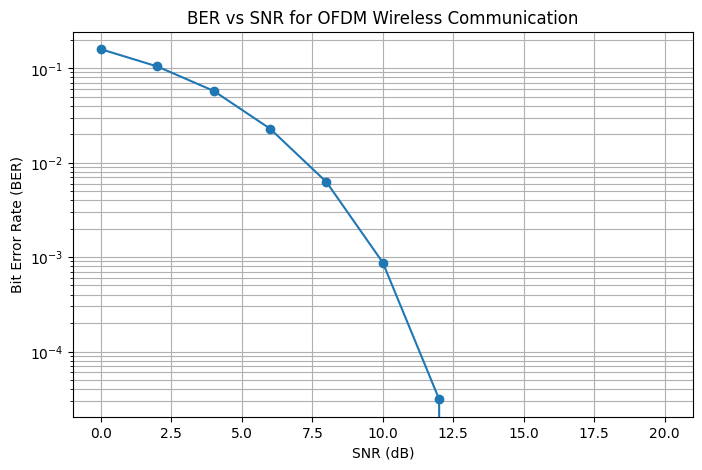

In [ ]:
# Plot BER vs SNR

plt.figure(figsize=(8, 5))

plt.semilogy(SNR_range, BER_values, 'o-')

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("BER vs SNR for OFDM Wireless Communication")
plt.grid(True, which="both")

plt.show()

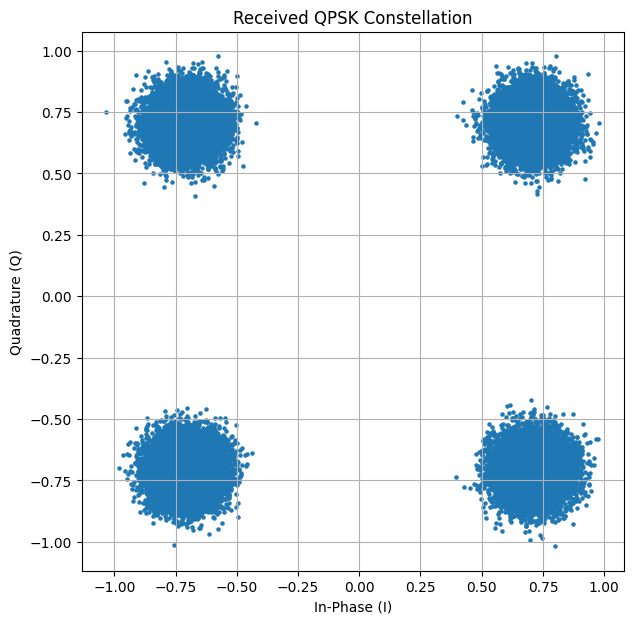

In [ ]:
# QPSK Constellation Diagram

plt.figure(figsize=(7, 7))

plt.scatter(
    received_qpsk[:5000].real,
    received_qpsk[:5000].imag,
    s=5
)

plt.xlabel("In-Phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("Received QPSK Constellation")
plt.grid(True)
plt.axis("equal")

plt.show()

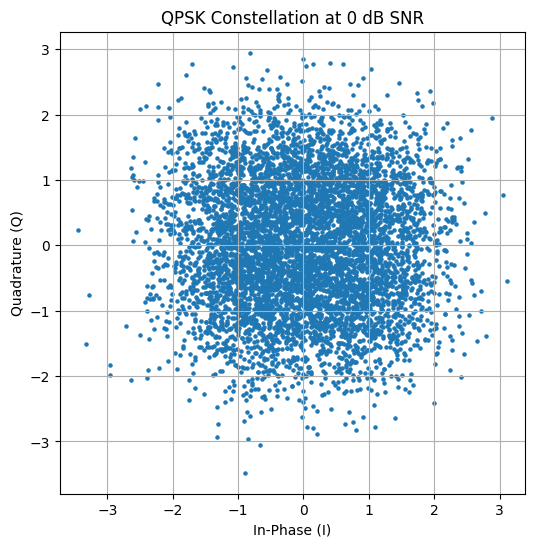

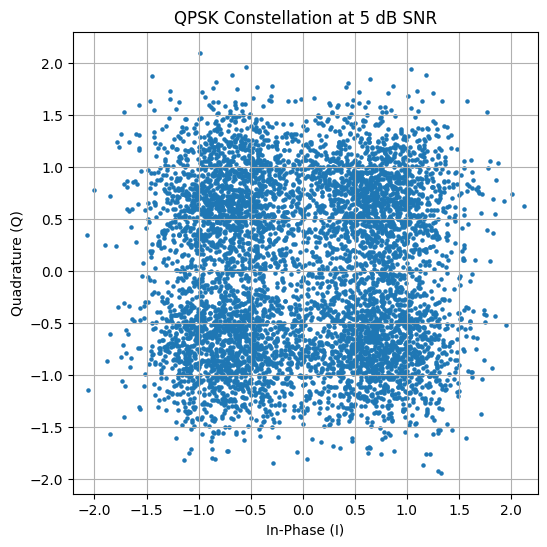

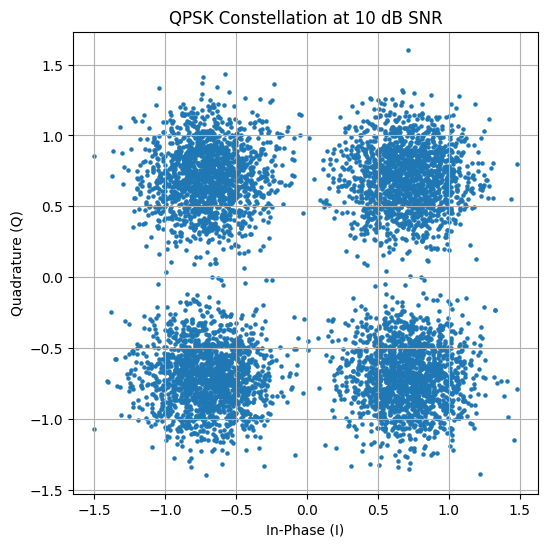

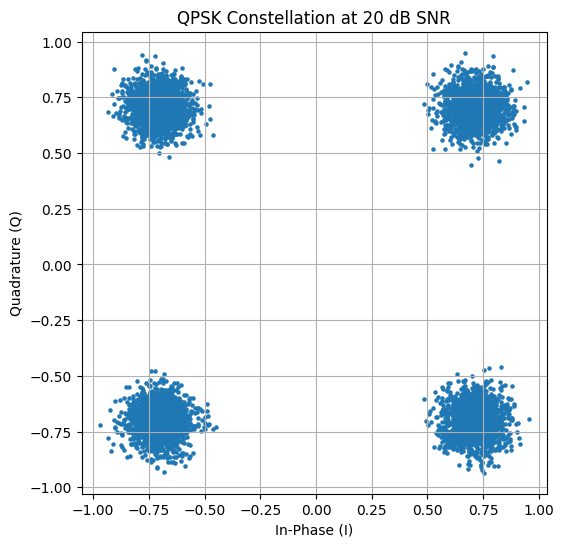

In [ ]:
# Compare QPSK constellation at different SNR levels

SNR_values = [0, 5, 10, 20]

for SNR_dB in SNR_values:

    signal_power = np.mean(np.abs(tx_signal) ** 2)
    noise_power = signal_power / (10 ** (SNR_dB / 10))

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(len(tx_signal)) +
        1j * np.random.randn(len(tx_signal))
    )

    rx_temp = tx_signal + noise

    # Reshape and remove CP
    rx_temp = rx_temp.reshape(num_symbols, N + CP)
    rx_temp = rx_temp[:, CP:]

    # FFT
    qpsk_temp = np.fft.fft(rx_temp, axis=1)

    plt.figure(figsize=(6, 6))

    plt.scatter(
        qpsk_temp[:100].real,
        qpsk_temp[:100].imag,
        s=5
    )

    plt.xlabel("In-Phase (I)")
    plt.ylabel("Quadrature (Q)")
    plt.title(f"QPSK Constellation at {SNR_dB} dB SNR")
    plt.grid(True)
    plt.axis("equal")

    plt.show()

In [ ]:
# Final BER Results Table

print("SNR (dB)    BER")
print("--------------------")

for snr, ber in zip(SNR_range, BER_values):
    print(f"{snr:>3}         {ber:.6f}")

SNR (dB)    BER
--------------------
  0         0.158547
  2         0.104133
  4         0.057414
  6         0.022852
  8         0.006234
 10         0.000875
 12         0.000031
 14         0.000000
 16         0.000000
 18         0.000000
 20         0.000000
